In [38]:
import os
os.environ['GROQ_API_KEY'] = os.getenv('GROQ_API_KEY')
os.environ['TAVILY_API_KEY'] = os.getenv('TAVILY_API_KEY')

In [39]:
from langchain_community.tools import WikipediaQueryRun, ArxivQueryRun
from langchain_community.utilities import WikipediaAPIWrapper, ArxivAPIWrapper


In [40]:
api_wrapper_arxiv = ArxivAPIWrapper(top_k_results=2, doc_content_chars_max=200)
arxiv = ArxivQueryRun(api_wrapper=api_wrapper_arxiv)

In [41]:
print(arxiv.name)

arxiv


In [42]:
import wikipedia
wikipedia.set_user_agent("ReActAgentNotebook/1.0 (your-email@example.com)")

api_wrapper_wiki = WikipediaAPIWrapper(top_k_results=1, doc_content_chars_max=500)
wiki = WikipediaQueryRun(api_wrapper=api_wrapper_wiki)
wiki.invoke("What is wikipedia")


'Page: Wikipedia\nSummary: Wikipedia is a free online encyclopedia written and maintained by a community of volunteer editors, known as Wikipedians, through open collaboration and the wiki software MediaWiki. Founded by Jimmy Wales and Larry Sanger in 2001, Wikipedia has been hosted since 2003 by the Wikimedia Foundation, an American nonprofit organization funded mainly by donations from readers. Wikipedia is the largest and most read reference work in history.\nInitially available only in English,'

In [43]:
wiki.invoke("What is wikipedia")

'Page: Wikipedia\nSummary: Wikipedia is a free online encyclopedia written and maintained by a community of volunteer editors, known as Wikipedians, through open collaboration and the wiki software MediaWiki. Founded by Jimmy Wales and Larry Sanger in 2001, Wikipedia has been hosted since 2003 by the Wikimedia Foundation, an American nonprofit organization funded mainly by donations from readers. Wikipedia is the largest and most read reference work in history.\nInitially available only in English,'

In [44]:
from langchain_community.tools.tavily_search import TavilySearchResults
tavily = TavilySearchResults()


In [45]:
tavily.invoke("Provide me the recent ai news for 3rd march 2025")

[{'title': 'Latest AI Updates For March 2025: What’s New In AI',
  'url': 'https://www.maayu.ai/ai-updates-march',
  'content': 'Ideogram is making waves with the launch of version 3.0 of its AI model, which brings significant boosts in photorealism, text rendering, and style consistency, surpassing rivals in human evaluations.\n Mistral AI has released Mistral Small 3.1—an open-source model featuring an impressive 24 billion parameters whose performance is equal to or better than GPT-4o mini. This model processes images and text, supports 128K token contexts, and runs efficiently even on modest hardware.\n Stability AI has introduced the Stable Virtual Camera—a unique tool that transforms 2D images into immersive 3D videos, with features like zooming and movement capabilities. This tool is being offered free for non-commercial use. [...] Google’s AI Studio and Gemini API now support YouTube URL inputs, allowing users to interact with video content. This feature enables AI to summarize

In [46]:
def add(a: float, b: float) -> float:
  """Add two numbers.

  Args:
    a: first number
    b: second number
  """
  return a + b

def subtract(a: float, b: float) -> float:
  """Subtract b from a.

  Args:
    a: first number
    b: number to subtract from a
  """
  return a - b

def multiply(a: float, b: float) -> float:
  """Multiply two numbers.

  Args:
    a: first number
    b: second number
  """
  return a * b

def divide(a: float, b: float) -> float | str:
  """Divide a by b.

  Args:
    a: dividend
    b: divisor
  """
  if b == 0:
    return "Error: division by zero"
  return a / b

In [47]:
tools = [arxiv, wiki, tavily, add, subtract, multiply, divide]

In [48]:
from langchain_groq import ChatGroq
# gpt-oss-120b tends to answer from memory; qwen3.8 reliably makes (parallel) tool calls
llm = ChatGroq(model="qwen/qwen3.8-27b")

In [49]:
llm_with_tools = llm.bind_tools(tools)

In [50]:
from pprint import pprint
from langchain_core.messages import AIMessage, HumanMessage
result = llm_with_tools.invoke([HumanMessage(content="What is the wikipedia")])

In [51]:
result.content

'Wikipedia is a free, multilingual, open-access online encyclopedia. It is one of the most visited websites in the world and is operated by the non-profit Wikimedia Foundation.\n\nHere are the key facts about it:\n\n*   **Founded:** January 15, 2001, by Jimmy Wales and Larry Sanger.\n*   **Name Origin:** A portmanteau of "wiki" (Hawaiian for "quick") and "encyclopedia."\n*   **Model:** It is a **wiki**, meaning anyone can edit its content. This collaborative model allows for rapid updates and a vast amount of information, though it requires community moderation to maintain accuracy.\n*   **Scope:** It exists in over 300 languages, with the English version being the largest.\n*   **Content:** It contains millions of articles covering topics from science and history to pop culture and geography.\n*   **Funding:** It is ad-free and funded primarily through donations to the Wikimedia Foundation.\n\nWikipedia is widely used as a reference tool for students, researchers, and the general publ

In [52]:
from langgraph.graph.message import add_messages
from typing import Annotated
from typing_extensions import TypedDict
from langchain_core.messages import AnyMessage

class State(TypedDict):
  messages: Annotated[list[AnyMessage], add_messages]

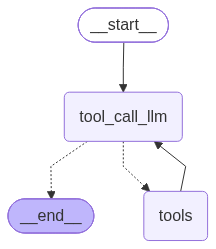

In [53]:
from IPython.display import display, Image
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

from langchain_core.messages import SystemMessage

sys_msg = SystemMessage(content=(
  "You are a helpful assistant. Always use the available tools to answer: "
  "use the math tools (add, subtract, multiply, divide) for any arithmetic, "
  "and wikipedia, arxiv or tavily for factual questions. Do not answer from memory."
))

def tool_call_llm(state: State):
  return {"messages": [llm_with_tools.invoke([sys_msg] + state["messages"])]}

builder = StateGraph(State)

builder.add_node("tool_call_llm", tool_call_llm)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "tool_call_llm")

builder.add_conditional_edges(
    "tool_call_llm",
    tools_condition
)

builder.add_edge("tools", 'tool_call_llm')


graph= builder.compile()


display(Image(graph.get_graph().draw_mermaid_png()))

In [54]:
messages = graph.invoke({"messages": HumanMessage(content="Provide me the top 10 recent AI news for March 3rd 2025, add 5 plus 5 and then multiply by 10")})

for message in messages["messages"]:
  message.pretty_print()

================================ Human Message =================================

Provide me the top 10 recent AI news for March 3rd 2025, add 5 plus 5 and then multiply by 10
================================== Ai Message ==================================

Let me search for the top AI news from March 3rd, 2025 and perform the calculations.
Tool Calls:
  tavily_search_results_json (kdr8gw437)
 Call ID: kdr8gw437
  Args:
    query: top AI news March 3 2025
  add (v1ek94kav)
 Call ID: v1ek94kav
  Args:
    a: 5
    b: 5
================================= Tool Message =================================
Name: tavily_search_results_json

[{"title": "https://aifamelee.io/ai-news-march-3-2025/", "url": "https://aifamelee.io/ai-news-march-3-2025", "content": "### 3. Google Gemini AI Expands Its Capabilities\n\nGoogle has announced exciting updates to its Gemini AI platform, unveiling new models designed for “Flash Thinking Experimental” and “Pro Deep Research.” These enhancements aim to push the